# 00 — Python em ação
## Da epidemia ao planejamento em saúde

**Pergunta:** como dados podem orientar vigilância, alocação de equipes e comunicação de risco?

A base desta oficina usa **dados oficiais**: notificações de dengue do SINAN/DATASUS (2024), população IBGE e renda domiciliar per capita do Censo 2022 (SIDRA). Os números são agregados por município e semana.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
sys.path.insert(0,str(ROOT))
from scripts.carregar_dados import caminhos
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid",palette="colorblind")
arq_casos, arq_municipios, FONTE = caminhos()
casos=pd.read_csv(arq_casos,parse_dates=["semana"],dtype={"codigo_ibge":"string"})
municipios=pd.read_csv(arq_municipios,dtype={"codigo_ibge":"string"})
print("Fonte selecionada:",FONTE)
casos.head()


Fonte selecionada: SINAN/DATASUS + IBGE (dados oficiais agregados)


,codigo_ibge,municipio,semana,casos
0,5200050,Abadia de Goiás,2024-01-14,10
1,5200050,Abadia de Goiás,2024-01-21,16
2,5200050,Abadia de Goiás,2024-01-28,6
3,5200050,Abadia de Goiás,2024-02-04,5
4,5200050,Abadia de Goiás,2024-02-11,15


In [2]:
print(f"{len(casos):,} linhas | {casos.municipio.nunique()} municípios | {casos.semana.min().date()} a {casos.semana.max().date()}")
casos.groupby("municipio",as_index=False).casos.sum().sort_values("casos",ascending=False).head(8)

7,673 linhas | 246 municípios | 2023-12-31 a 2024-12-22


,municipio,casos
94,Goiânia,57890
14,Anápolis,39050
15,Aparecida de Goiânia,24933
131,Luziânia,17109
163,Novo Gama,11603
194,Rio Verde,10170
245,Águas Lindas de Goiás,9935
237,Valparaíso de Goiás,8940


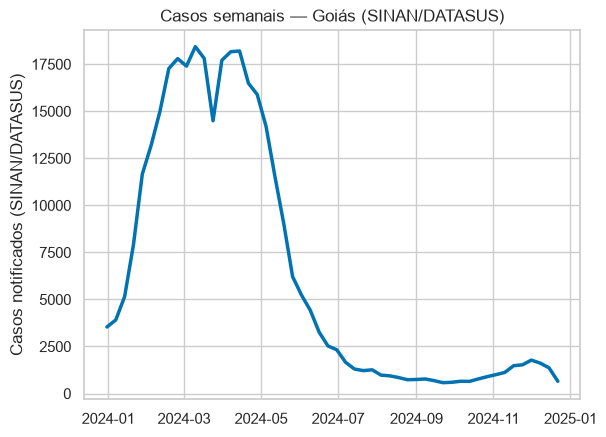

In [3]:
go=casos.groupby("semana",as_index=False).casos.sum()
sns.lineplot(data=go,x="semana",y="casos",linewidth=2.5)
plt.title("Casos semanais — Goiás (SINAN/DATASUS)")
plt.xlabel(""); plt.ylabel("Casos notificados (SINAN/DATASUS)"); plt.show()

### Para discutir

- Um pico significa necessariamente epidemia?
- Contagens absolutas permitem comparar municípios de tamanhos diferentes?
- Qual decisão de gestão este gráfico pode apoiar — e qual ele não pode?